In [1]:
import torch
import matplotlib.pyplot as plt
import numpy as np
from engression.models import StoNet
from engression.loss_func import energy_loss_two_sample
from scipy.stats import gamma

In [2]:
shape = 2.
scale = 3.
gamma_dist = torch.distributions.Gamma(concentration=shape, rate=1.0/scale)

In [3]:
# generate data
n = 1000
x = torch.Tensor(gamma_dist.sample((n,1)))

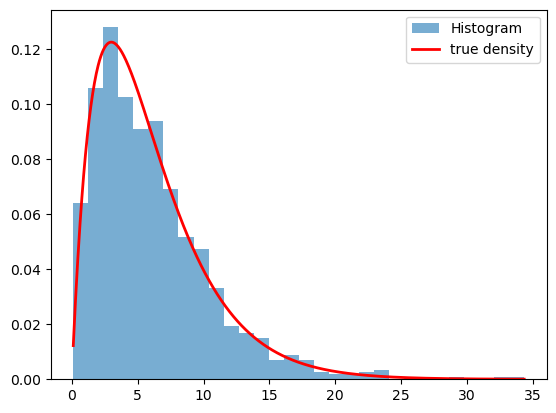

In [4]:
plt.hist(x.squeeze(1), bins=30, density=True, alpha=0.6, label='Histogram')

# Generate a range of values for plotting the theoretical density curve
xx = np.linspace(min(x), max(x), 1000)
pdf = gamma.pdf(xx, a=shape, scale=scale)

# Overlay the theoretical gamma density curve
plt.plot(xx, pdf, 'r-', lw=2, label='true density')
plt.legend(); plt.show()

In [120]:
# build model
model = StoNet(in_dim=0, out_dim=1, num_layer=4, hidden_dim=400, noise_dim=1, add_bn=False)#, out_act='softplus')
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)

In [121]:
# training
model.train()
for i in range(1000):
    optimizer.zero_grad()
    sample1 = model(n)
    sample2 = model(n)
    loss, s1, s2 = energy_loss_two_sample(x, sample1, sample2)
    loss.backward()
    optimizer.step()
    if i == 0 or (i + 1) % 100 == 0:
        print(f'Iter {i + 1} | loss: {loss.item():.4f}, s1: {s1.item():.4f}, s2: {s2.item():.4f}')

Iter 1 | loss: 6.0862, s1: 6.0998, s2: 0.0273
Iter 100 | loss: 2.4017, s1: 4.7249, s2: 4.6464
Iter 200 | loss: 2.4580, s1: 4.5815, s2: 4.2470
Iter 300 | loss: 2.1916, s1: 4.5138, s2: 4.6446
Iter 400 | loss: 2.3687, s1: 4.5802, s2: 4.4231
Iter 500 | loss: 2.4329, s1: 4.7187, s2: 4.5716
Iter 600 | loss: 2.3195, s1: 4.5231, s2: 4.4072
Iter 700 | loss: 2.3654, s1: 4.5436, s2: 4.3564
Iter 800 | loss: 2.2780, s1: 4.5259, s2: 4.4958
Iter 900 | loss: 2.3222, s1: 4.5035, s2: 4.3626
Iter 1000 | loss: 2.3500, s1: 4.7089, s2: 4.7179


In [127]:
# evaluation
model.eval()
with torch.no_grad():
    sample = model(n)
sum(sample < 0)

tensor([0])

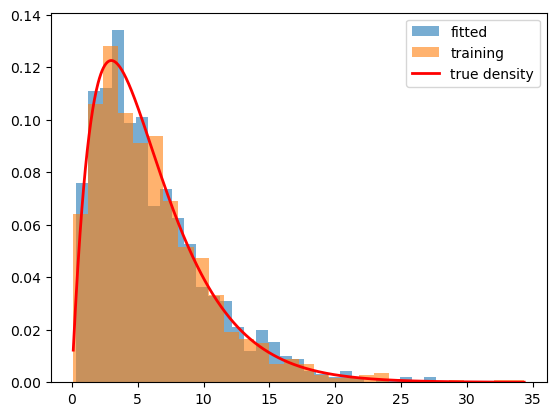

In [8]:
plt.hist(sample.squeeze(1), bins=30, density=True, alpha=0.6, label='fitted')
plt.hist(x.squeeze(1), bins=30, density=True, alpha=0.6, label='training')
xx = np.linspace(min(x), max(x), 1000)
pdf = gamma.pdf(xx, a=shape, scale=scale)
# Overlay the theoretical gamma density curve
plt.plot(xx, pdf, 'r-', lw=2, label='true density')
plt.legend(); plt.show()

In [16]:
sample1 = model(n)
sample2 = model(n)
loss, s1, s2 = energy_loss_two_sample(x, sample1, sample2)

In [14]:
loss

tensor(2.3133, grad_fn=<UnbindBackward0>)

In [167]:
n = 5000

Generated 5000 1D samples using sklearn with shape: (5000, 1)
Flattened shape for plotting: (5000,)


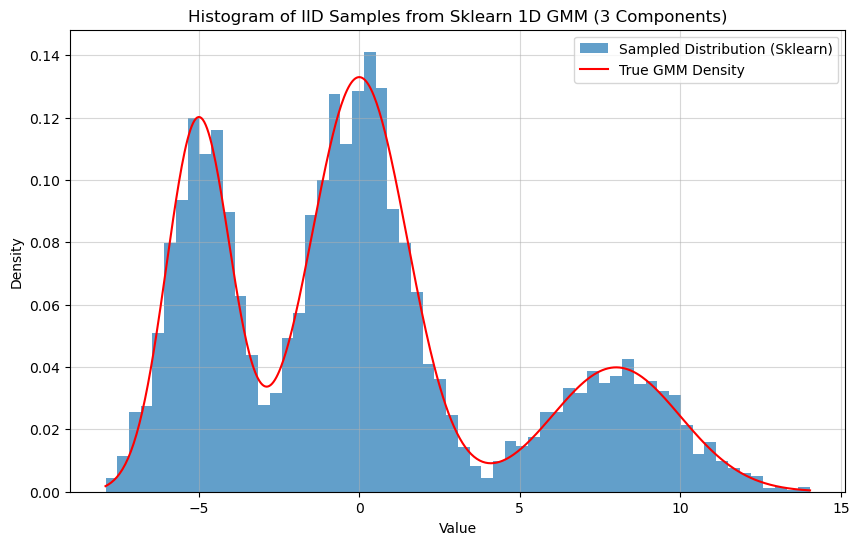

In [168]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.mixture import GaussianMixture
from scipy.stats import norm # For plotting true density

# --- 1. Define 1D GMM Parameters (using sklearn expected shapes) ---
weights = np.array([0.3, 0.5, 0.2])
n_components = len(weights)
n_features = 1 # Explicitly 1 dimension

# Means (shape: n_components x n_features)
means_sklearn = np.array([[-5.0], [0.0], [8.0]])

# Standard Deviations
std_devs = np.array([1.0, 1.5, 2.0])
# Variances (shape: n_components x n_features x n_features)
variances_sklearn = (std_devs**2).reshape(-1, 1, 1) # Shape (3, 1, 1)
# Precisions (inverse variances) (shape: n_components x n_features x n_features)
precisions_sklearn = (1.0 / (std_devs**2)).reshape(-1, 1, 1) # Shape (3, 1, 1)

n_samples = n

# --- 2. Create and Configure a GaussianMixture object ---
gmm = GaussianMixture(
    n_components=n_components,
    covariance_type='full', # 'full', 'diag', or 'spherical' work for 1D
                           # 'diag' or 'spherical' might feel more natural here
    weights_init=weights,
    means_init=means_sklearn,
    precisions_init=precisions_sklearn
)

# Manually set fitted parameters (as we didn't call fit())
gmm.weights_ = weights
gmm.means_ = means_sklearn
# Need to set covariances_ as well, even if precisions_init was used
gmm.covariances_ = variances_sklearn
# For internal consistency, also set precisions_cholesky_
# In 1D, cholesky(precision) is sqrt(precision) = 1/std_dev
gmm.precisions_cholesky_ = (1.0 / std_devs).reshape(-1, 1, 1)

# --- 3. Generate Samples using the .sample() method ---
# Output shape will be (n_samples, n_features) -> (n_samples, 1)
samples_sklearn, component_labels = gmm.sample(n_samples)

# Flatten samples for easier plotting/analysis in 1D
samples_sklearn_flat = samples_sklearn.flatten()

print(f"Generated {n_samples} 1D samples using sklearn with shape: {samples_sklearn.shape}")
print(f"Flattened shape for plotting: {samples_sklearn_flat.shape}")

# --- 4. Visualize the Samples (Histogram) ---
plt.figure(figsize=(10, 6))
plt.hist(samples_sklearn_flat, bins=60, density=True, alpha=0.7, label='Sampled Distribution (Sklearn)')

# Plot the true density curve (using original means/std_devs for clarity)
x_plot = np.linspace(samples_sklearn_flat.min(), samples_sklearn_flat.max(), 500)
true_density = np.zeros_like(x_plot)
means_1d = means_sklearn.flatten() # Get back to 1D array for norm.pdf
std_devs_1d = np.sqrt(variances_sklearn.reshape(-1)) # Get back to 1D array

for k in range(n_components):
    true_density += weights[k] * norm.pdf(x_plot, loc=means_1d[k], scale=std_devs_1d[k])

plt.plot(x_plot, true_density, 'r-', label='True GMM Density')
plt.title(f'Histogram of IID Samples from Sklearn 1D GMM ({n_components} Components)')
plt.xlabel('Value')
plt.ylabel('Density')
plt.grid(True, alpha=0.5)
plt.legend()
plt.show()

In [169]:
y = torch.Tensor(samples_sklearn)
# build model
model = StoNet(in_dim=0, out_dim=1, num_layer=4, hidden_dim=100, noise_dim=1, add_bn=False)#, out_act='softplus')
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)
# training
model.train()
for i in range(1000):
    optimizer.zero_grad()
    sample1 = model(n)
    sample2 = model(n)
    loss, s1, s2 = energy_loss_two_sample(y, sample1, sample2)
    loss.backward()
    optimizer.step()
    if i == 0 or (i + 1) % 100 == 0:
        print(f'Iter {i + 1} | loss: {loss.item():.4f}, s1: {s1.item():.4f}, s2: {s2.item():.4f}')
# evaluation
model.eval()
with torch.no_grad():
    sample = model(n)

Iter 1 | loss: 3.6937, s1: 3.7147, s2: 0.0421
Iter 100 | loss: 2.6907, s1: 5.3737, s2: 5.3661
Iter 200 | loss: 2.6548, s1: 5.4371, s2: 5.5647
Iter 300 | loss: 2.6312, s1: 5.2969, s2: 5.3314
Iter 400 | loss: 2.6315, s1: 5.3018, s2: 5.3406
Iter 500 | loss: 2.6859, s1: 5.4729, s2: 5.5741
Iter 600 | loss: 2.6474, s1: 5.2746, s2: 5.2543
Iter 700 | loss: 2.6388, s1: 5.2957, s2: 5.3138
Iter 800 | loss: 2.6901, s1: 5.2986, s2: 5.2169
Iter 900 | loss: 2.7023, s1: 5.3095, s2: 5.2145
Iter 1000 | loss: 2.6730, s1: 5.2450, s2: 5.1439


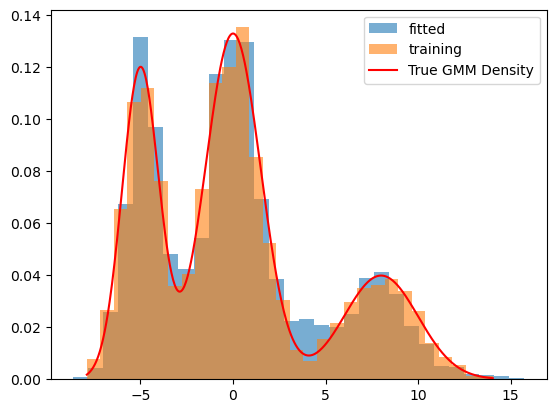

In [170]:
plt.hist(sample.squeeze(1), bins=30, density=True, alpha=0.6, label='fitted')
plt.hist(y.squeeze(1), bins=30, density=True, alpha=0.6, label='training')
xx = np.linspace(min(x), max(x), 1000)
pdf = gamma.pdf(xx, a=shape, scale=scale)
plt.plot(x_plot, true_density, 'r-', label='True GMM Density')
plt.legend(); plt.show()

Iter 1 | loss: 1.1927, s1: 1.3451, s2: 0.3049
Iter 100 | loss: 0.7610, s1: 1.5298, s2: 1.5377
Iter 200 | loss: 0.7554, s1: 1.4928, s2: 1.4748
Iter 300 | loss: 0.7669, s1: 1.5271, s2: 1.5204
Iter 400 | loss: 0.7590, s1: 1.5235, s2: 1.5291
Iter 500 | loss: 0.7574, s1: 1.5159, s2: 1.5169
Iter 600 | loss: 0.7563, s1: 1.5284, s2: 1.5442
Iter 700 | loss: 0.7629, s1: 1.5317, s2: 1.5376
Iter 800 | loss: 0.7545, s1: 1.5241, s2: 1.5392
Iter 900 | loss: 0.7484, s1: 1.5183, s2: 1.5398
Iter 1000 | loss: 0.7593, s1: 1.5408, s2: 1.5628


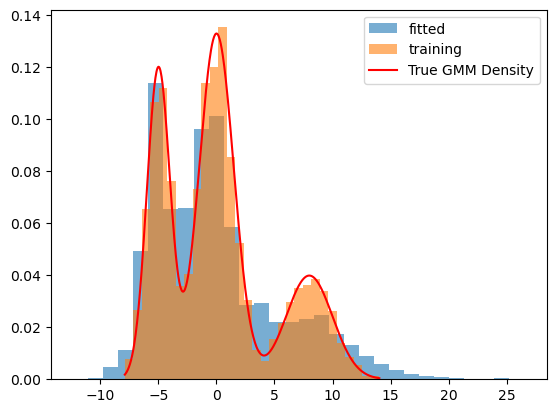

In [173]:
y = torch.Tensor(samples_sklearn)
# build model
model = StoNet(in_dim=0, out_dim=1, num_layer=4, hidden_dim=100, noise_dim=1, add_bn=False)#, out_act='softplus')
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)
# training
model.train()
for i in range(1000):
    optimizer.zero_grad()
    sample1 = model(n)
    sample2 = model(n)
    loss, s1, s2 = energy_loss_two_sample(y, sample1, sample2, beta = 0.3)
    loss.backward()
    optimizer.step()
    if i == 0 or (i + 1) % 100 == 0:
        print(f'Iter {i + 1} | loss: {loss.item():.4f}, s1: {s1.item():.4f}, s2: {s2.item():.4f}')
# evaluation
model.eval()
with torch.no_grad():
    sample = model(n)
plt.hist(sample.squeeze(1), bins=30, density=True, alpha=0.6, label='fitted')
plt.hist(y.squeeze(1), bins=30, density=True, alpha=0.6, label='training')
xx = np.linspace(min(x), max(x), 1000)
pdf = gamma.pdf(xx, a=shape, scale=scale)
plt.plot(x_plot, true_density, 'r-', label='True GMM Density')
plt.legend(); plt.show()

In [174]:
help(StoNet)

Help on class StoNet in module engression.models:

class StoNet(StoNetBase)
 |  StoNet(in_dim, out_dim, num_layer=2, hidden_dim=100, noise_dim=100, add_bn=True, out_act=None, resblock=False, noise_all_layer=True, out_bias=True, verbose=True)
 |
 |  Stochastic neural network.
 |
 |  Args:
 |      in_dim (int): input dimension
 |      out_dim (int): output dimension
 |      num_layer (int, optional): number of layers. Defaults to 2.
 |      hidden_dim (int, optional): number of neurons per layer. Defaults to 100.
 |      noise_dim (int, optional): noise dimension. Defaults to 100.
 |      add_bn (bool, optional): whether to add BN layer. Defaults to True.
 |      out_act (str, optional): output activation function. Defaults to None.
 |      resblock (bool, optional): whether to use residual blocks. Defaults to False.
 |
 |  Method resolution order:
 |      StoNet
 |      StoNetBase
 |      torch.nn.modules.module.Module
 |      builtins.object
 |
 |  Methods defined here:
 |
 |  __init__